# 🐧 ASSIGNMENT — The Penguin Field Guide (EDA)

| | |
|---|---|
| **Student Name** | Muhammad Ahmed |
| **Student ID** |  3840586074193|
| **Due Date** | _____________________________ |
| **Total Marks** | **100** (+10 bonus) |

---
### 🎬 The scenario
> *You're a **field biologist** at the Palmer Research Station in Antarctica. Your team has measured **344 penguins** across three species — **Adélie, Chinstrap, and Gentoo** — recording bill size, flipper length, and body mass.*
>
> *Next season, junior researchers need to identify species **in the field, from measurements alone.** Your assignment: use EDA to discover each species' "measurement fingerprint" and produce a simple **field guide** for telling them apart.*

### 🎯 What you'll be graded on
Not just working code — **correct analysis and clear, evidence-based conclusions.** Every chart should help answer: *what makes each species distinct?*

### 📤 Submission
Run all cells before submitting (Kernel → Restart & Run All). Answer every **✍️ Written Answer** box in your own words. Save and submit this `.ipynb` file with all outputs visible.

### 📋 Mark breakdown
| Part | Task | Marks |
|---|---|---|
| **A** | Setup & load the data | 10 |
| **B** | Clean the data (justify your choices) | 15 |
| **C** | Categorical EDA (species & islands) | 15 |
| **D** | Numerical EDA (distributions & correlations) | 20 |
| **E** | Species fingerprints (the core analysis) | 25 |
| **F** | Written field guide (your conclusions) | 15 |
| **Bonus** | Identify a mystery penguin | +10 |

---

## Part A — Setup & Load  *(10 marks)*

In [ ]:
# TODO (5): import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
# Set seaborn theme to 'whitegrid'.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')


In [ ]:
# TODO (5): Load the penguins dataset (offline):  df = sns.load_dataset('penguins')
# Print its shape, and show the first 5 rows. Then run df.info().
df = sns.load_dataset('penguins')
print(f'shape of data is {df.shape}')
print(f'first 5 row \n {df.head(5)}' )
print(df.info)



shape of data is (344, 7)
first 5 row 
   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
<bound method DataFrame.info of     species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
3    Adelie  Torgersen       

## Part B — Clean the Data  *(15 marks)*
Real field data has gaps. Handle them thoughtfully — and **justify** each choice.

In [ ]:
# TODO (5): Print the number of missing values in each column.
print(df.isnull().sum())


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [ ]:
# TODO (10):
# - A few rows are missing ALL measurements → drop those rows.
# - Some rows are missing 'sex' → drop those rows too (we need it later).
# Hint: df = df.dropna().reset_index(drop=True)
# Print the shape before and after.

# TODO (10):

# Shape before removing missing values
print("Shape before:", df.shape)

# Remove rows containing missing values
df = df.dropna().reset_index(drop=True)

# Shape after removing missing values
print("Shape after:", df.shape)

Shape before: (344, 7)
Shape after: (333, 7)


**✍️ Written Answer B (marks for reasoning):** How many rows did you remove, and what % of the data was that? Was dropping them safe? Why?
*Your answer:* _______________ I removed 11 rows, which is about 3.2% of the original 344 rows. Dropping these rows was reasonably safe because the dataset is still large enough for analysis, and the missing rows did not contain complete information needed for our analysis. We also need the sex column later, so removing rows with missing values keeps the dataset consistent.


## Part C — Categorical EDA  *(15 marks)*
*How many of each species, and where do they live?*

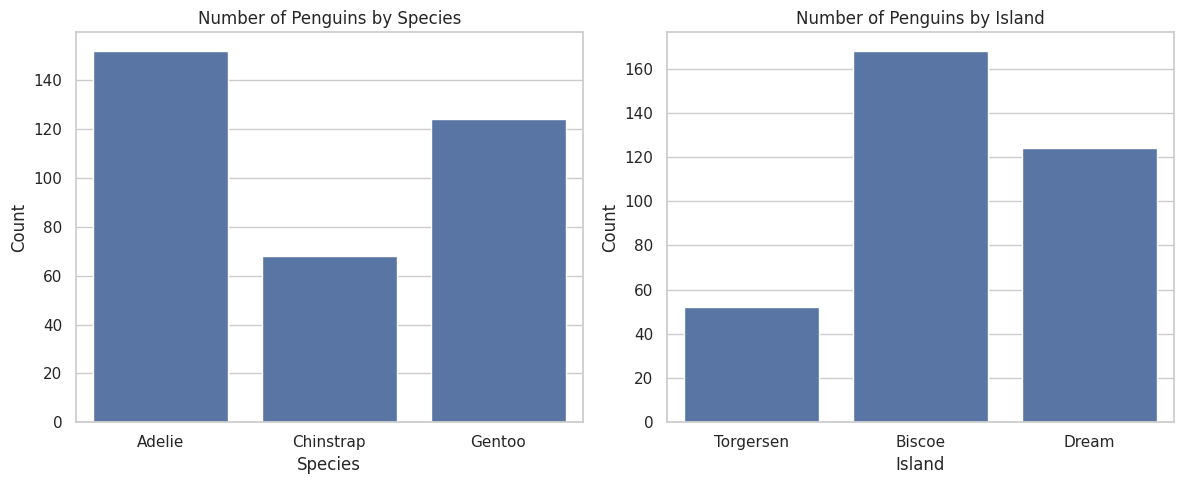

In [ ]:
# TODO (8): In a 1×2 grid, plot a countplot of 'species' and a countplot of 'island'.
# Give each a clear title.
  # Create a 1x2 grid
 # Create a 1x2 grid
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Species countplot
sns.countplot(data=df, x="species", ax=axes[0])
axes[0].set_title("Number of Penguins by Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Count")

# Island countplot
sns.countplot(data=df, x="island", ax=axes[1])
axes[1].set_title("Number of Penguins by Island")
axes[1].set_xlabel("Island")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0


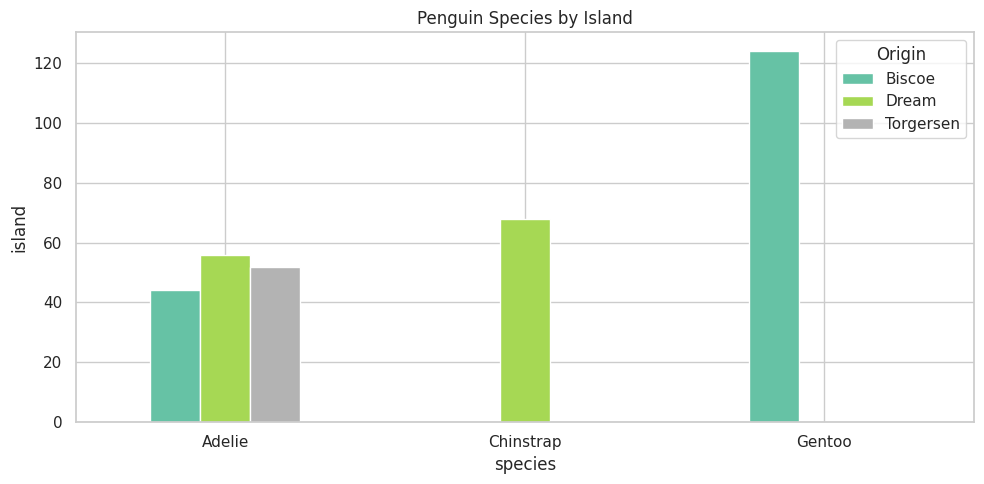

In [ ]:
# TODO (7): Make a crosstab of species vs island (pd.crosstab) and plot it as a bar chart.
# Which islands does each species live on?
spec_isl=pd.crosstab(df['species'], df['island'])
print(spec_isl)
spec_isl.plot(kind='bar', figsize=(10, 5), colormap='Set2')
plt.title('Penguin Species by Island')
plt.xlabel('species');
plt.ylabel('island')
plt.xticks(rotation=0);
plt.legend(title='Origin')
plt.tight_layout();
plt.show()


**✍️ Written Answer C:** Which species is the most common? Is any species found on only ONE island? (That's a huge clue for identification.)
*Your answer:* _______________ Gentoo is the most common species in the cleaned dataset. Chinstrap is found only on Dream Island, while Adelie is found on all three islands and Gentoo is found only on Biscoe Island. Island distribution is therefore a useful clue for identifying species.

## Part D — Numerical EDA  *(20 marks)*
*Understand the four body measurements.*

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


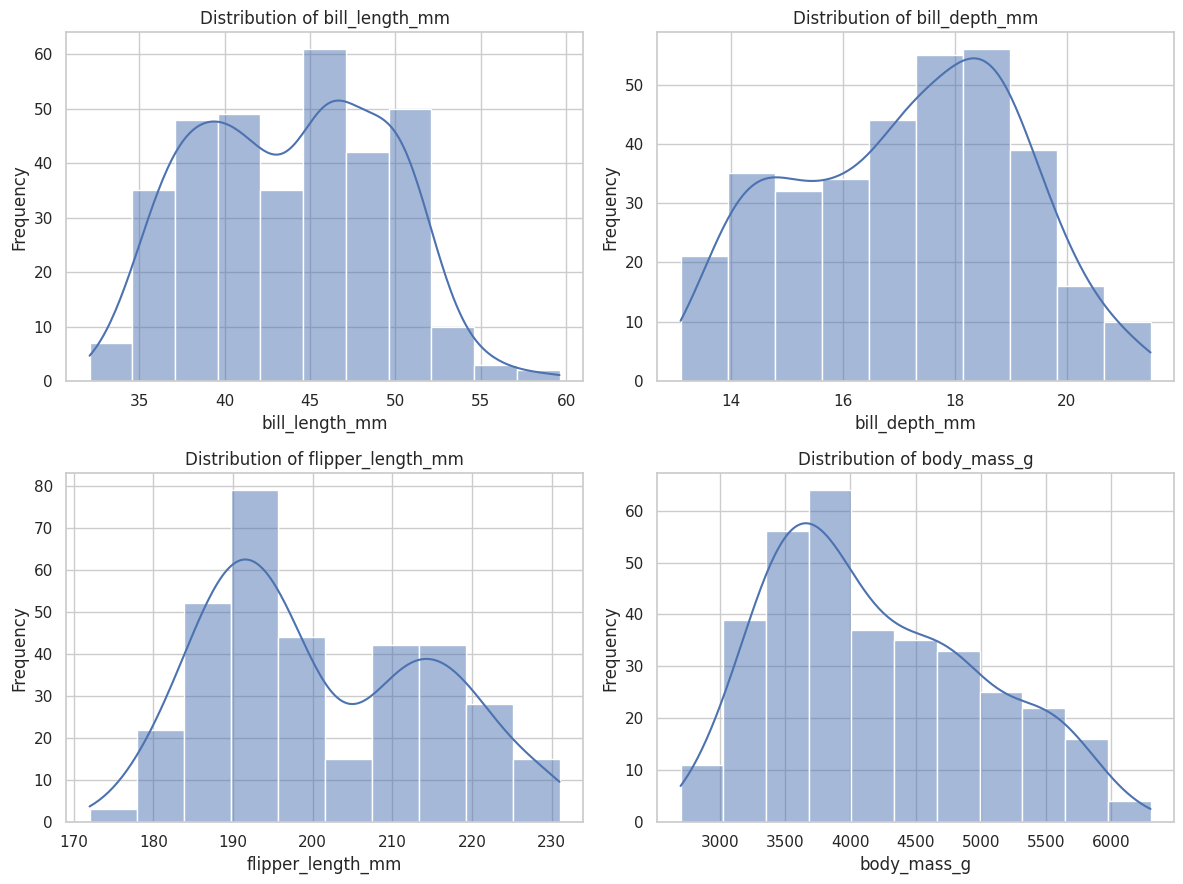

In [ ]:
# TODO (10): For each of the 4 measurements
#   (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g),
# plot a histogram with kde=True. Arrange as a 2×2 grid.
# Look: are any distributions clearly split into groups (bumps)? That hints at species!

num_col=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
print(num_col)

# Create 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flatten(), num_col):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

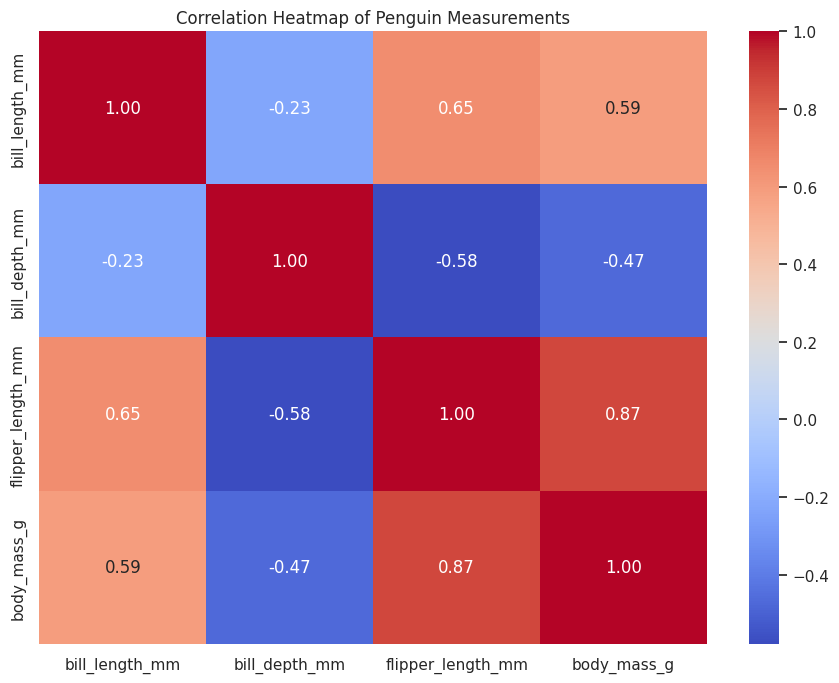

In [ ]:
# TODO (10): Plot a correlation heatmap of the 4 numeric measurements (annot=True).
# Which two measurements are most strongly related?
# Calculate correlation matrix
corr = df[num_col].corr()

# Plot heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Penguin Measurements")
plt.tight_layout()
plt.show()


**✍️ Written Answer D:** Which two measurements have the strongest positive correlation, and does that make biological sense (think: bigger penguin → ?)
*Your answer:* _______________

## Part E — Species Fingerprints  *(25 marks)*  🎯 *the core of the assignment*
*This is where you crack the case: which measurements tell the species apart?*

In [ ]:
# TODO (9): Compute the MEAN of each measurement grouped by species.
#   df.groupby('species')[num_cols].mean()
# This table is the heart of your field guide — study it.
# Calculate mean measurements for each species
species_means = df.groupby("species")[num_col].mean()

# Display the result
species_means



,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


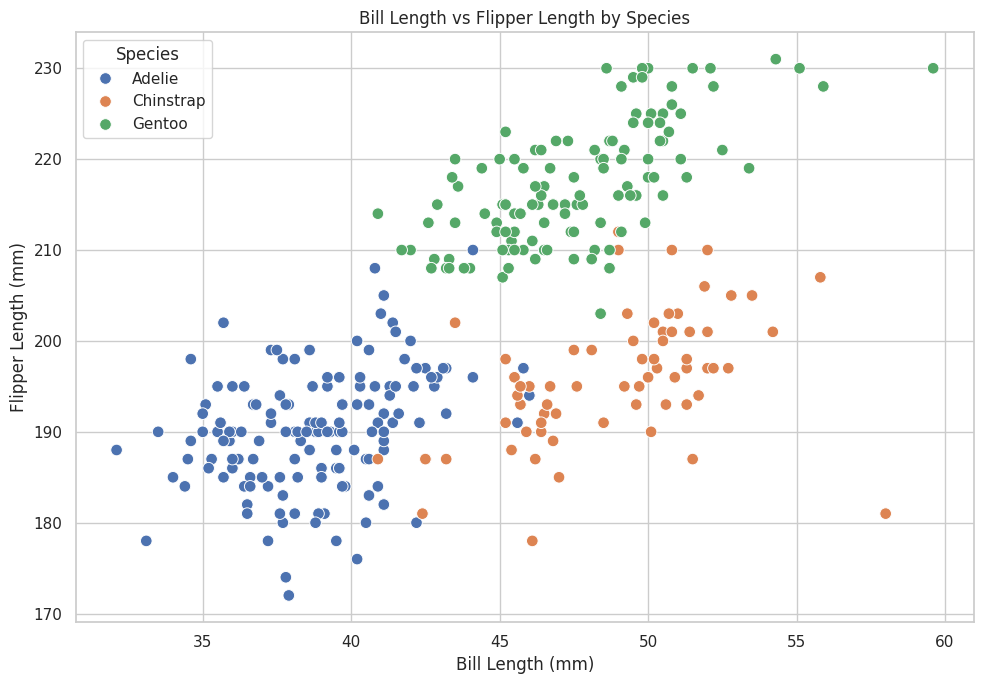

In [ ]:
# TODO (8): Make a scatter plot of bill_length_mm (x) vs flipper_length_mm (y),
# coloured by species (hue='species'). Do the species form separate clusters?
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    s=70
)

plt.title("Bill Length vs Flipper Length by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Species")

plt.tight_layout()
plt.show()



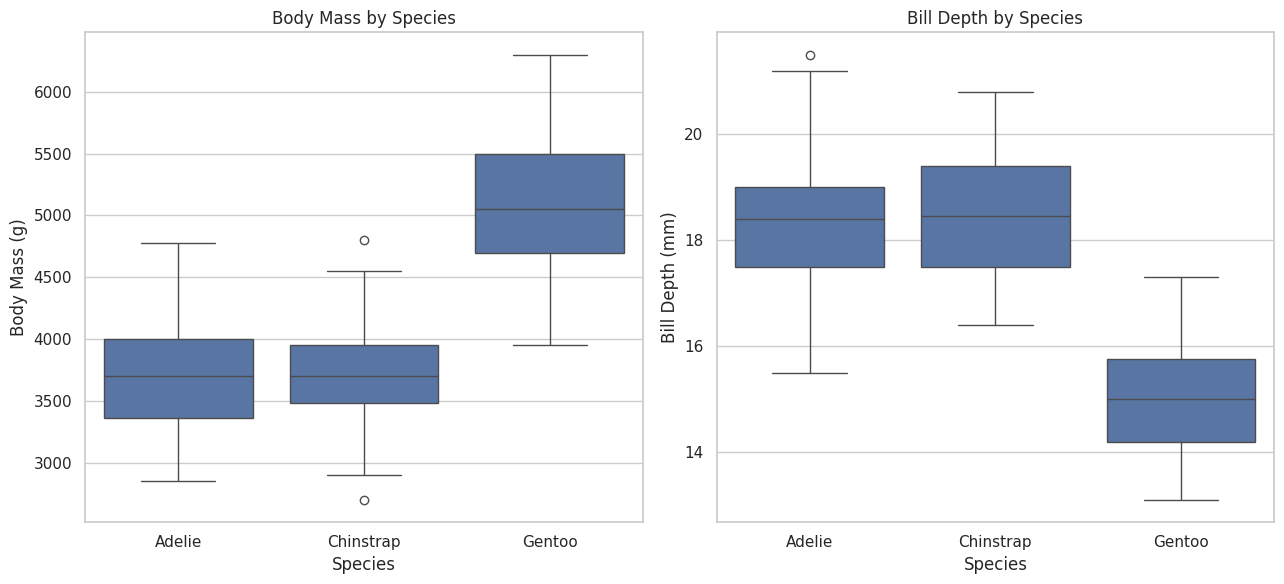

In [ ]:
# TODO (8): Make boxplots of body_mass_g by species, and bill_depth_mm by species
# (1×2 grid). Which species is the clear outlier in size?
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Body mass
sns.boxplot(
    data=df,
    x="species",
    y="body_mass_g",
    ax=axes[0]
)

axes[0].set_title("Body Mass by Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Body Mass (g)")

# Bill depth
sns.boxplot(
    data=df,
    x="species",
    y="bill_depth_mm",
    ax=axes[1]
)

axes[1].set_title("Bill Depth by Species")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Bill Depth (mm)")

plt.tight_layout()
plt.show()


**✍️ Written Answer E:** Describe each species in ONE sentence using measurements. For example: *"Gentoos are the ___ (heaviest/lightest), with the ___ flippers and a ___ bill."* Do this for all three species.
*Adélie:* _______________
*Chinstrap:* _______________
*Gentoo:* _______________

## Part F — Your Field Guide  *(15 marks)*
Write a short **field guide** (4–6 sentences) that a junior researcher could use to identify a penguin from measurements alone. Base every rule on your charts. A good guide gives simple decision rules, e.g. *"If flipper length > 210mm, it's almost certainly a Gentoo."*

**✍️ Your Field Guide:**

> _______________________________________________
>
> _______________________________________________
>
> _______________________________________________

## 🌟 Bonus — Identify the Mystery Penguin  *(+10 marks)*
A researcher measured a penguin but forgot to record its species:

> **bill_length = 46 mm, bill_depth = 15 mm, flipper_length = 217 mm, body_mass = 5000 g**

Using your fingerprints from Part E, decide which species it is — and **justify with the data** (which measurements gave it away?).

In [ ]:
# TODO (bonus): Justify your answer with code — e.g. compare this penguin's numbers
# to the species means, or plot it on top of your scatter from Part E.
# Mystery penguin
mystery = pd.Series({
    "bill_length_mm": 46,
    "bill_depth_mm": 15,
    "flipper_length_mm": 217,
    "body_mass_g": 5000
})

# Compare mystery penguin with species means
comparison = species_means.copy()

comparison["bill_length_difference"] = abs(
    comparison["bill_length_mm"] - mystery["bill_length_mm"]
)

comparison["bill_depth_difference"] = abs(
    comparison["bill_depth_mm"] - mystery["bill_depth_mm"]
)

comparison["flipper_difference"] = abs(
    comparison["flipper_length_mm"] - mystery["flipper_length_mm"]
)

comparison["body_mass_difference"] = abs(
    comparison["body_mass_g"] - mystery["body_mass_g"]
)

comparison



,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,bill_length_difference,bill_depth_difference,flipper_difference,body_mass_difference
species,,,,,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384,7.176027,3.347260,26.897260,1293.835616
Chinstrap,48.833824,18.420588,195.823529,3733.088235,2.833824,3.420588,21.176471,1266.911765
Gentoo,47.568067,14.996639,217.235294,5092.436975,1.568067,0.003361,0.235294,92.436975


**✍️ Bonus Answer:** This penguin is a **_______**, because _______________

---
### ✅ Before you submit
- [ ] Every `# TODO` cell has working code
- [ ] Every ✍️ Written Answer is filled in
- [ ] You ran **Kernel → Restart & Run All** with no errors
- [ ] Charts have titles and are readable

*Good luck, field biologist!* 🐧